### 서울시 교통사고 시각화

In [78]:
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns


In [3]:
traffic_Seoul = pd.read_csv("../Data/Seoul_2005_2025.csv")
traffic_Seoul.head()

,년도,월,자치구명,발생건수,사망자수,부상자수
0,2005,1,강남구,212,2,330
1,2005,1,강동구,101,4,138
2,2005,1,강북구,88,0,142
3,2005,1,강서구,128,0,210
4,2005,1,관악구,97,1,135


서울열린데이터 광장

In [4]:
traffic_Seoul1 = pd.read_csv("../Data/월별+교통사고+현황_20261111204536.csv")
traffic_Seoul1.head()

,시점,자치구별(1),자치구별(2),발생건수 (건),사망자수 (명),부상자수 (명)
0,2005. 01,합계,소계,2836,31,4411
1,2005. 01,합계,종로구,93,2,138
2,2005. 01,합계,중구,97,1,156
3,2005. 01,합계,용산구,129,3,199
4,2005. 01,합계,성동구,98,2,133


In [5]:
traffic_Seoul.tail()

,년도,월,자치구명,발생건수,사망자수,부상자수
6295,2025,12,용산구,92,1,119
6296,2025,12,은평구,94,1,110
6297,2025,12,종로구,79,2,96
6298,2025,12,중구,88,0,112
6299,2025,12,중랑구,101,1,122


In [6]:
# 소계 행 삭제
traffic_Seoul1.drop(
    traffic_Seoul1[traffic_Seoul1['자치구별(2)'] == '소계'].index,
    inplace=True
)

# 연간 합계 행 삭제
traffic_Seoul1.drop(
    traffic_Seoul1[traffic_Seoul1['시점'] == '2025'].index,
    inplace=True
)

# 시점에서 년도와 월 추출
def get_year(date):
    return date[:4]

def get_month(date):
    return date[-2:]

traffic_Seoul1['년도'] = traffic_Seoul1['시점'].apply(get_year).astype(int)
traffic_Seoul1['월'] = traffic_Seoul1['시점'].apply(get_month).astype(int)

# 필요한 열만 선택
traffic_Seoul1 = traffic_Seoul1[
    ['년도', '월', '자치구별(2)', '발생건수 (건)', '사망자수 (명)', '부상자수 (명)']
].copy()

# 열 이름 변경
traffic_Seoul1.rename(
    columns={
        '자치구별(2)': '자치구명',
        '발생건수 (건)': '발생건수',
        '사망자수 (명)': '사망자수',
        '부상자수 (명)': '부상자수'
    },
    inplace=True
)

# 사망자수의 '-'를 0으로 변경
traffic_Seoul1['사망자수'] = traffic_Seoul1['사망자수'].replace('-', 0)

# 숫자 자료형으로 변경
traffic_Seoul1['발생건수'] = traffic_Seoul1['발생건수'].astype(int)
traffic_Seoul1['사망자수'] = traffic_Seoul1['사망자수'].astype(int)
traffic_Seoul1['부상자수'] = traffic_Seoul1['부상자수'].astype(int)

# 정렬 및 인덱스 정리
traffic_Seoul1 = traffic_Seoul1.sort_values(by=['년도', '월', '자치구명'])
traffic_Seoul1 = traffic_Seoul1.reset_index(drop=True)

traffic_Seoul1.head()

,년도,월,자치구명,발생건수,사망자수,부상자수
0,2005,1,강남구,212,2,330
1,2005,1,강동구,101,4,138
2,2005,1,강북구,88,0,142
3,2005,1,강서구,128,0,210
4,2005,1,관악구,97,1,135


In [7]:
traffic_Seoul1.info()

<class 'pandas.DataFrame'>
RangeIndex: 6300 entries, 0 to 6299
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   년도      6300 non-null   int64
 1   월       6300 non-null   int64
 2   자치구명    6300 non-null   str  
 3   발생건수    6300 non-null   int64
 4   사망자수    6300 non-null   int64
 5   부상자수    6300 non-null   int64
dtypes: int64(5), str(1)
memory usage: 353.1 KB


---
#### 컬럼별 데이터 확인

In [8]:
# 년도별 빈도수
traffic_Seoul1.년도.value_counts().sort_index()

년도
2005    300
2006    300
2007    300
2008    300
2009    300
2010    300
2011    300
2012    300
2013    300
2014    300
2015    300
2016    300
2017    300
2018    300
2019    300
2020    300
2021    300
2022    300
2023    300
2024    300
2025    300
Name: count, dtype: int64

In [9]:
# 월별 빈도수
traffic_Seoul1.월.value_counts().sort_index()

월
1     525
2     525
3     525
4     525
5     525
6     525
7     525
8     525
9     525
10    525
11    525
12    525
Name: count, dtype: int64

In [10]:
# 자치구명별 빈도수
traffic_Seoul1.자치구명.value_counts().sort_index()

자치구명
강남구     252
강동구     252
강북구     252
강서구     252
관악구     252
광진구     252
구로구     252
금천구     252
노원구     252
도봉구     252
동대문구    252
동작구     252
마포구     252
서대문구    252
서초구     252
성동구     252
성북구     252
송파구     252
양천구     252
영등포구    252
용산구     252
은평구     252
종로구     252
중구      252
중랑구     252
Name: count, dtype: int64

---
#### 자치구명별 발생건수

In [11]:
# 자치구명별 발생건수의 평균을 DataFrame으로 제작
regionAcc_mean = traffic_Seoul1.groupby('자치구명', as_index=False)['발생건수'].mean()

# 발생건수 기준으로 내림차순 정렬
regionAcc_mean.sort_values(by='발생건수', ascending=False)

,자치구명,발생건수
0,강남구,302.515873
17,송파구,217.964286
19,영등포구,185.134921
14,서초구,176.428571
10,동대문구,144.511905
3,강서구,144.134921
24,중랑구,138.107143
8,노원구,128.678571
4,관악구,127.793651
12,마포구,127.420635


In [12]:
# 자치구별 표준편차를 DataFrame으로
regionAcc_std = traffic_Seoul1.groupby('자치구명', as_index=False)['발생건수'].std()
regionAcc_std

,자치구명,발생건수
0,강남구,37.170166
1,강동구,19.146334
2,강북구,17.817840
3,강서구,21.464639
4,관악구,27.464811
5,광진구,31.251072
6,구로구,17.680977
7,금천구,14.185473
8,노원구,20.133515
9,도봉구,18.282750


In [13]:
# 자치구별 발생건수의 변동계수
# 변동계수 = 표준편차 / 평균
region_cv = regionAcc_std.발생건수 / regionAcc_mean.발생건수
region_cv

0     0.122870
1     0.165855
2     0.182443
3     0.148920
4     0.214915
5     0.306383
6     0.145951
7     0.185768
8     0.156464
9     0.266886
10    0.169334
11    0.173420
12    0.203055
13    0.169144
14    0.161405
15    0.164261
16    0.185312
17    0.128383
18    0.166798
19    0.131980
20    0.195432
21    0.236312
22    0.242736
23    0.226531
24    0.200473
Name: 발생건수, dtype: float64

In [14]:
regionAcc = pd.DataFrame(
    {
    '자치구명' : regionAcc_mean.자치구명,
    '변동계수' : region_cv.values
    }
)
regionAcc.sort_values(by='변동계수', ascending=True)

,자치구명,변동계수
0,강남구,0.122870
17,송파구,0.128383
19,영등포구,0.131980
6,구로구,0.145951
3,강서구,0.148920
8,노원구,0.156464
14,서초구,0.161405
15,성동구,0.164261
1,강동구,0.165855
18,양천구,0.166798


#### 자치구별 부상자수 변동계수 구하기

In [ ]:
regionInjure_mean = traffic_Seoul1.groupby('자치구명', as_index=False)['부상자수'].mean()
regionInjure_mean.sort_values(by='부상자수', ascending=False)

,자치구명,부상자수
0,강남구,427.996032
17,송파구,307.742063
14,서초구,269.615079
19,영등포구,265.781746
3,강서구,202.011905
12,마포구,189.634921
24,중랑구,188.972222
10,동대문구,188.769841
8,노원구,181.900794
6,구로구,172.968254


In [16]:
regionInjure_std = traffic_Seoul1.groupby('자치구명', as_index=False)['부상자수'].std()
regionInjure_std

,자치구명,부상자수
0,강남구,51.085702
1,강동구,29.616203
2,강북구,27.111490
3,강서구,33.863269
4,관악구,43.329089
5,광진구,49.436097
6,구로구,31.095903
7,금천구,25.431607
8,노원구,31.772255
9,도봉구,27.921601


In [17]:
regionInjure_cv = regionInjure_std.부상자수 / regionInjure_mean.부상자수
regionInjure_cv

0     0.119360
1     0.186521
2     0.206302
3     0.167630
4     0.251021
5     0.345765
6     0.179778
7     0.227310
8     0.174668
9     0.295926
10    0.192076
11    0.181435
12    0.242521
13    0.212381
14    0.173691
15    0.184243
16    0.209850
17    0.133559
18    0.182976
19    0.150313
20    0.230183
21    0.246648
22    0.264012
23    0.243261
24    0.223376
Name: 부상자수, dtype: float64

In [18]:
regionInjure = pd.DataFrame(
    {
        '자치구명' : regionInjure_mean.자치구명,
        '변동계수' : regionInjure_cv.values
    }
)
regionInjure.sort_values('변동계수', ascending=True)

,자치구명,변동계수
0,강남구,0.119360
17,송파구,0.133559
19,영등포구,0.150313
3,강서구,0.167630
14,서초구,0.173691
8,노원구,0.174668
6,구로구,0.179778
11,동작구,0.181435
18,양천구,0.182976
15,성동구,0.184243


In [19]:
# 교통사고 발생건수와 부상자수의 관계(상관계수)
traffic_Seoul1.발생건수.corr(traffic_Seoul1.부상자수)

np.float64(0.9801643167014666)

In [20]:
traffic_Seoul1.부상자수.corr(traffic_Seoul1.사망자수)

np.float64(0.26056986009030636)

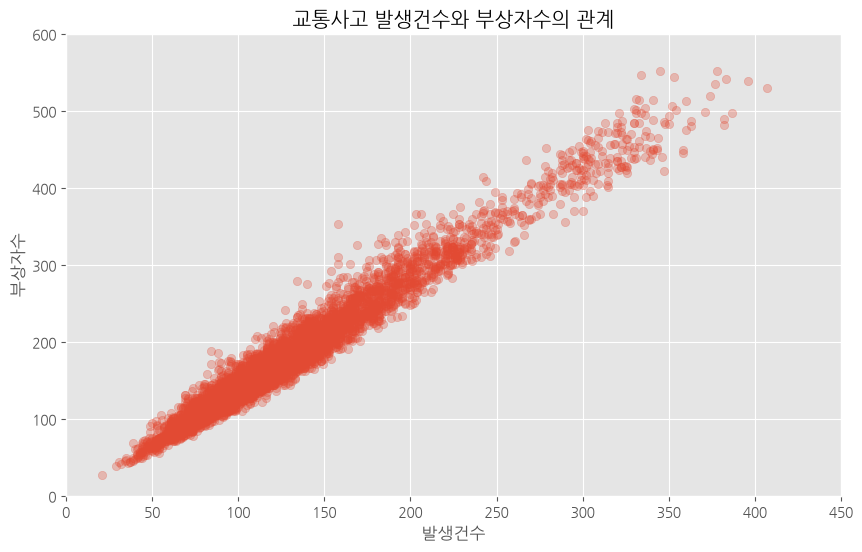

In [ ]:
# 발생건수와 부상자수의 산포도
plt.style.use('ggplot')

# 발생건수와 부상자수의 산점도
plt.figure(figsize=(10, 6))

plt.scatter(
    traffic_Seoul1['발생건수'],
    traffic_Seoul1['부상자수'],
    alpha=0.3
)

plt.title('교통사고 발생건수와 부상자수의 관계')
plt.xlabel('발생건수')
plt.ylabel('부상자수')
plt.xlim(0, 450)
plt.ylim(0, 600)
plt.show()

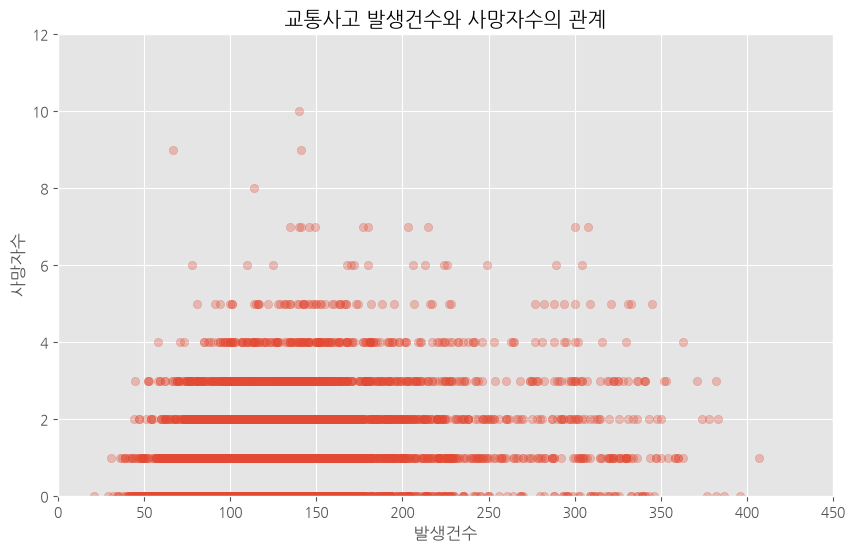

In [ ]:
plt.style.use('ggplot')

# 발생건수와 부상자수의 산점도
plt.figure(figsize=(10, 6))

plt.scatter(
    traffic_Seoul1['발생건수'],
    traffic_Seoul1['사망자수'],
    alpha=0.3
)

plt.title('교통사고 발생건수와 사망자수의 관계')
plt.xlabel('발생건수')
plt.ylabel('사망자수')
plt.xlim(0, 450)
plt.ylim(0, 12)
plt.show()

---
#### 자치구별 사망자수 변동계수

In [33]:
regionDeath_mean = traffic_Seoul1.groupby('자치구명', as_index=False)['사망자수'].mean()
regionDeath_std = traffic_Seoul1.groupby('자치구명', as_index=False)['사망자수'].std()

regionDeath_cv = regionDeath_std.사망자수 / regionDeath_mean.사망자수

regionDeath = pd.DataFrame(
    {
        '자치구명' : regionDeath_mean.자치구명,
        '변동계수' : regionDeath_cv.values
    }
)
regionDeath.sort_values('변동계수', ascending=True)

,자치구명,변동계수
19,영등포구,0.790683
0,강남구,0.822963
17,송파구,0.845154
1,강동구,0.865989
4,관악구,0.886767
3,강서구,0.906104
14,서초구,0.943892
20,용산구,0.961631
10,동대문구,0.982689
22,종로구,0.995078


----
#### 2019년 데이터만 추출하기

In [ ]:
traffic_Seoul_2019 = traffic_Seoul[traffic_Seoul.년도 == 2019]
traffic_Seoul_2019.head()

,년도,월,자치구명,발생건수,사망자수,부상자수
4200,2019,1,강남구,281,2,412
4201,2019,1,강동구,98,1,115
4202,2019,1,강북구,88,0,114
4203,2019,1,강서구,136,1,179
4204,2019,1,관악구,104,0,148


In [41]:
# Index 정리
traffic_Seoul_2019.reset_index(drop=True, inplace=True)
traffic_Seoul_2019

,년도,월,자치구명,발생건수,사망자수,부상자수
0,2019,1,강남구,281,2,412
1,2019,1,강동구,98,1,115
2,2019,1,강북구,88,0,114
3,2019,1,강서구,136,1,179
4,2019,1,관악구,104,0,148
...,...,...,...,...,...,...
295,2019,12,용산구,89,1,124
296,2019,12,은평구,103,1,139
297,2019,12,종로구,100,0,142
298,2019,12,중구,113,0,182


In [49]:
# 자치구별 발생건수, 사망자수, 부상자수 집계하기
traffic_anal = pd.pivot_table(
                        traffic_Seoul_2019,
                        index='자치구명',
                        aggfunc='sum'
)
traffic_anal = traffic_anal[['발생건수', '부상자수', '사망자수']]
traffic_anal.head()

,발생건수,부상자수,사망자수
자치구명,,,
강남구,3722,5182,14
강동구,1414,1910,11
강북구,1277,1706,7
강서구,1829,2491,20
관악구,1363,1755,10


In [52]:
# 위도, 경도를 포함한 데이터 불러오기
seoul_limit = pd.read_csv("../Data/seoul.csv", encoding='euc-kr')
seoul_limit.columns = ['자치구명', 'lon', 'lat']
seoul_limit.head()

,자치구명,lon,lat
0,강남구,127.0475,37.51731
1,강동구,127.1238,37.53013
2,강북구,127.0255,37.63975
3,관악구,126.9515,37.47834
4,구로구,126.8875,37.49547


In [ ]:
# traffic_anal와 seoul_limit 병합하기
data_result = pd.merge(traffic_anal, seoul_limit, on='자치구명')
data_result.head()

,자치구명,발생건수,부상자수,사망자수,lon,lat
0,강남구,3722,5182,14,127.0475,37.51731
1,강동구,1414,1910,11,127.1238,37.53013
2,강북구,1277,1706,7,127.0255,37.63975
3,강서구,1829,2491,20,126.8496,37.55094
4,관악구,1363,1755,10,126.9515,37.47834


In [56]:
data_result.info()

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   자치구명    25 non-null     str    
 1   발생건수    25 non-null     int64  
 2   부상자수    25 non-null     int64  
 3   사망자수    25 non-null     int64  
 4   lon     25 non-null     float64
 5   lat     25 non-null     float64
dtypes: float64(2), int64(3), str(1)
memory usage: 1.5 KB


#### folium을 사용하기 위해 int를 float로 변환

In [57]:
data_result.발생건수 = data_result.발생건수.astype(float)
data_result.부상자수 = data_result.부상자수.astype(float)
data_result.사망자수 = data_result.사망자수.astype(float)

In [58]:
data_result.info()

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   자치구명    25 non-null     str    
 1   발생건수    25 non-null     float64
 2   부상자수    25 non-null     float64
 3   사망자수    25 non-null     float64
 4   lon     25 non-null     float64
 5   lat     25 non-null     float64
dtypes: float64(5), str(1)
memory usage: 1.5 KB


---
#### folium을 통한 시각화

In [63]:
import folium
import json

In [ ]:
# 서울시 지도 생성
map = folium.Map(
    location=[37.5502, 126.982],
    zoom_start=11
)

# 발생건수와 사망자수의 최댓값
max_accidents = data_result['발생건수'].max()
max_deaths = data_result['사망자수'].max()

for n in data_result.index:
    # 구청 위치
    location = [
        data_result.loc[n, 'lat'],
        data_result.loc[n, 'lon']
    ]

    name = data_result.loc[n, '자치구명']
    accidents = data_result.loc[n, '발생건수']
    deaths = data_result.loc[n, '사망자수']

    # 구청 마커
    folium.Marker(
        location,
        popup=f'{name}<br>발생건수: {accidents:,.0f}건<br>사망자수: {deaths:,.0f}명'
    ).add_to(map)

    # 발생건수: 파란 원
    folium.CircleMarker(
        location,
        radius=(accidents / max_accidents) ** 0.5 * 25 if max_accidents > 0 else 0,
        color='blue',
        fill=True,
        fill_color='blue',
        fill_opacity=0.2
    ).add_to(map)

    # 사망자수: 빨간 원
    folium.CircleMarker(
        location,
        radius=(deaths / max_deaths) ** 0.5 * 12 if max_deaths > 0 else 0,
        color='red',
        fill=True,
        fill_color='red',
        fill_opacity=0.5
    ).add_to(map)

map

In [76]:
# 서울시 지도 생성
map = folium.Map(
    location=[37.5502, 126.982],
    zoom_start=11
)

# 발생건수 상위 10개 자치구
top_accidents = data_result.sort_values(
    by='발생건수', ascending=False
).head(10)

# 사망자수 상위 10개 자치구
top_deaths = data_result.sort_values(
    by='사망자수', ascending=False
).head(10)

# 발생건수와 사망자수의 최댓값
max_accidents = data_result['발생건수'].max()
max_deaths = data_result['사망자수'].max()

# 상위 10개 중 하나에라도 포함된 자치구의 마커 표시
for n in data_result.index:
    if n in top_accidents.index or n in top_deaths.index:
        location = [
            data_result.loc[n, 'lat'],
            data_result.loc[n, 'lon']
        ]

        name = data_result.loc[n, '자치구명']
        accidents = data_result.loc[n, '발생건수']
        deaths = data_result.loc[n, '사망자수']

        folium.Marker(
            location,
            popup=f'{name}<br>발생건수: {accidents:,.0f}건<br>사망자수: {deaths:,.0f}명'
        ).add_to(map)

# 발생건수 상위 10개: 파란 원
for n in top_accidents.index:
    location = [
        top_accidents.loc[n, 'lat'],
        top_accidents.loc[n, 'lon']
    ]

    accidents = top_accidents.loc[n, '발생건수']

    folium.CircleMarker(
        location,
        radius=(accidents / max_accidents) ** 0.5 * 25 if max_accidents > 0 else 0,
        color='blue',
        fill=True,
        fill_color='blue',
        fill_opacity=0.2
    ).add_to(map)

# 사망자수 상위 10개: 빨간 원
for n in top_deaths.index:
    location = [
        top_deaths.loc[n, 'lat'],
        top_deaths.loc[n, 'lon']
    ]

    deaths = top_deaths.loc[n, '사망자수']

    folium.CircleMarker(
        location,
        radius=(deaths / max_deaths) ** 0.5 * 12 if max_deaths > 0 else 0,
        color='red',
        fill=True,
        fill_color='red',
        fill_opacity=0.5
    ).add_to(map)

map

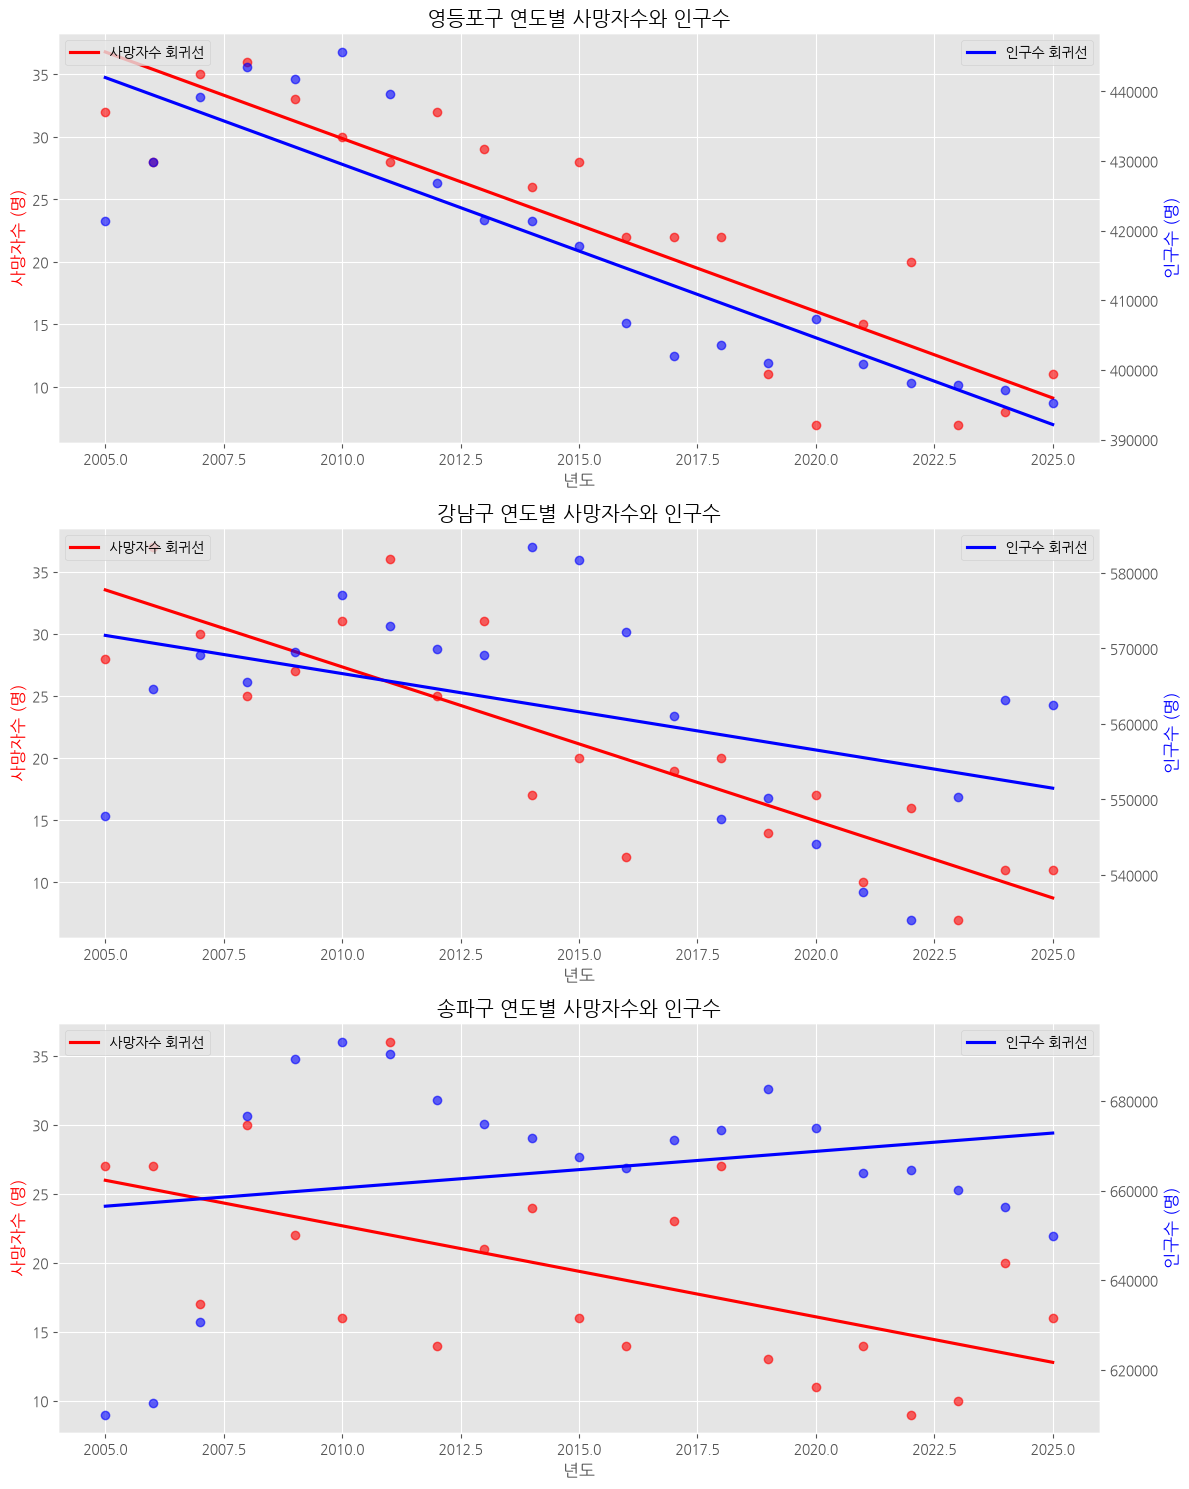

In [79]:
# 그래프 스타일
plt.style.use('ggplot')

# 자치구별 연도별 인구 데이터 불러오기
population = pd.read_csv('../Data/등록인구_20261112173735.csv')

# 필요한 열 선택 및 이름 변경
population = population[['동별(2)', '시점', '계 (명)']].copy()
population.columns = ['자치구명', '년도', '인구수']

# 년도와 인구수를 숫자로 변경
population['년도'] = pd.to_numeric(population['년도'], errors='coerce')
population['인구수'] = pd.to_numeric(population['인구수'], errors='coerce')

# 자치구별·연도별 사망자수 합계
yearly_deaths = traffic_Seoul1.groupby(
    ['자치구명', '년도'], as_index=False
)['사망자수'].sum()

# 전체 기간 사망자수 합계가 많은 자치구 상위 3개
top3 = yearly_deaths.groupby('자치구명')['사망자수'].sum()
top3 = top3.sort_values(ascending=False).head(3)

# 연도별 사망자수와 인구수 합치기
result = pd.merge(
    yearly_deaths,
    population,
    on=['자치구명', '년도'],
    how='inner'
)

# 상위 3개 자치구 그래프
fig, axes = plt.subplots(3, 1, figsize=(12, 15))

for i, region in enumerate(top3.index):
    # 해당 자치구 자료만 선택
    region_data = result[result['자치구명'] == region].sort_values('년도')

    # 왼쪽 축: 사망자수
    ax1 = axes[i]

    sns.regplot(
        data=region_data,
        x='년도',
        y='사망자수',
        ax=ax1,
        color='red',
        scatter_kws={'alpha': 0.6},
        line_kws={'label': '사망자수 회귀선'},
        ci=None
    )

    ax1.set_title(f'{region} 연도별 사망자수와 인구수')
    ax1.set_xlabel('년도')
    ax1.set_ylabel('사망자수 (명)', color='red')

    # 오른쪽 축: 인구수
    ax2 = ax1.twinx()

    sns.regplot(
        data=region_data,
        x='년도',
        y='인구수',
        ax=ax2,
        color='blue',
        scatter_kws={'alpha': 0.6},
        line_kws={'label': '인구수 회귀선'},
        ci=None
    )

    ax2.set_ylabel('인구수 (명)', color='blue')
    ax2.grid(False)

    ax1.legend(loc='upper left')
    ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()